# Interpreta un banco de flotación como respuesta cinética

Nivel: 1. Requisitos previos: Ninguno; comienza aquí. Tiempo de lectura: 18 minutos.

## Objetivos

Ejecuta el rougher Cu-Mo y distingue su curva batch virtual de la respuesta del banco alimentado de forma continua. Comprende por qué recuperación versus tiempo es una respuesta de proceso, no una animación decorativa.

## Preparación

```bash
pip install numpy==2.2.6 scipy==1.17.1 pandas==2.2.3 matplotlib==3.11.2 nbclient==0.11.0 nbformat==5.11.1 ipykernel==7.4.0 SALib==1.6.0
```

El pipeline OreFlow se importa desde `data-pipeline/`; este notebook nunca instala paquetes.

Configura las importaciones y registra versiones. Este paso hace reproducible la ejecución del método.

In [1]:
# Importa herramientas de análisis y registra sus versiones exactas.
import importlib.metadata
import json
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Resuelve el pipeline local desde la estructura relativa del repositorio.
repo = Path('../../../').resolve()
sys.path.insert(0, str(repo / 'data-pipeline'))
for package in ('numpy', 'scipy', 'pandas', 'matplotlib', 'nbclient', 'nbformat', 'ipykernel'):
    print(package, importlib.metadata.version(package))

numpy 2.2.6
scipy 1.17.1
pandas 2.2.3
matplotlib 3.11.2
nbclient 0.11.0
nbformat 5.11.1
ipykernel 7.4.0


## Datos

Responsable: autores de OreFlow; escenario Cu-Mo de autoría propia en `data/derived/cases/copper_molybdenum.json`, licencia MIT del proyecto. El motor genera la curva cinética; no se midió en laboratorio ni planta. Repositorio: https://github.com/fsantibanezleal/CAOS_OreFlow.

## Método

OreFlow agrega tasas por clase mediante $R_b(t)=\sum_j c_jx_j(1-e^{-k_jt})/\sum_j c_jx_j$. Un banco continuo tiene otra distribución temporal y se calcula por separado. Llama a `simulate` y al constructor `trace` de producción.

Selecciona un caso Cu-Mo de autoría propia y ejecuta los mismos métodos de circuito y trace del pipeline de datos OreFlow.

In [2]:
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate
from pipeline.engine.trace import trace

# Paso ejecutable del método OreFlow explicado en la celda anterior.
case = next(item for item in CASES if item.id == 'copper_molybdenum')
result = simulate(case.ore, case.plant, case.nominal)
record = trace(result, case.nominal, case.plant.family)
kinetics = record['methods']['kinetics']
print('familia:', record['family'], '| status:', kinetics['status'])
print('bank residence (min):', round(kinetics['bank']['residence_min'], 2))
print('engine rougher recovery (%):', round(kinetics['bank']['engine_rougher_pct'], 2))

familia: rougher | status: computed
bank residence (min): 29.16
engine rougher recovery (%): 94.01


Grafica por separado la curva batch virtual y el perfil del banco continuo; comparten unidades, pero describen modelos de residencia distintos.

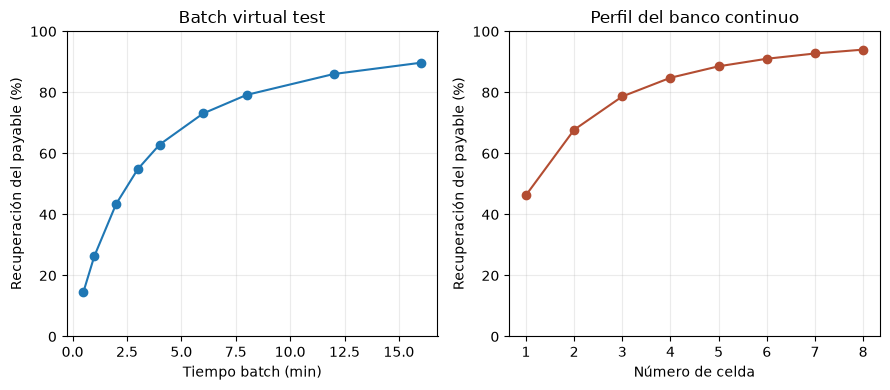

In [3]:
# Grafica por separado la curva batch virtual y el perfil del banco continuo; comparten unidades, pero describen modelos de residencia distintos.
bank = record['curves']['bank_profile']
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].plot(kinetics['times_min'], kinetics['batch_recovery_pct'], 'o-', label='Batch virtual')
axes[0].set(xlabel='Tiempo batch (min)', ylabel='Recuperación del payable (%)', title='Batch virtual test')
axes[1].plot([v['cell'] for v in bank], [100 * v['recovery'] for v in bank], 'o-', color='#b34d32')
axes[1].set(xlabel='Número de celda', ylabel='Recuperación del payable (%)', title='Perfil del banco continuo')
for ax in axes: ax.set_ylim(0, 100); ax.grid(True, alpha=.25)
fig.tight_layout()

Lee juntos alimentación rougher, concentrado y relave. Ley y recuperación responden preguntas distintas.

In [4]:
# Lee juntos alimentación rougher, concentrado y relave.
streams = record['streams']
rows = [(name, streams[name]['solids_tph'], streams[name]['grades'][kinetics['species']])
        for name in ('rougher_feed', 'rougher_concentrate', 'rougher_tail') if name in streams]
display(pd.DataFrame(rows, columns=['Flujo', 'Sólidos (t/h)', f"{kinetics['species']} grade (%)"]))

,Flujo,Sólidos (t/h),Cu grade (%)
0,rougher_feed,687.297218,0.620996
1,rougher_concentrate,61.023570,6.574911
2,rougher_tail,626.273648,0.040852


## Resultados

La curva batch es una prueba virtual generada por la distribución de tasas del motor; el perfil de banco aplica un modelo de residencia continua. La diferencia no es evidencia de planta. Ley del concentrado y recuperación son resultados distintos.

## Resumen

Ejecutaste el solver y revisaste sus respuestas batch y de banco simuladas. El registro no es información de laboratorio, y recorrer la flowsheet no equivale al tiempo físico de planta.

## Referencias

- https://doi.org/10.1016/0301-7516(81)90019-3
- https://doi.org/10.1016/0301-7516(81)90019-3
- https://doi.org/10.1016/0301-7516(81)90019-3